# Introduction

After working with state-space models and being able to construct the likelihood function across different model types (deterministic and stochastic), it is now time to identify the model parameters using this likelihood function.

The idea is that for each set of parameters proposed you can compute the corresponidng likelihood. We can then run an optimization routine that iterates and adapts these parameters based on their likelihoods.

The objective is to find the set of parameters that maximizes the likelihood function or equivelantly minimizes its negative.

The objective of this notebook is to undergo such identification problem. We will be identifying a determinisitc model only and not a stochastic one. In fact the process is quite similar in the two cases the only difference is in the likelihood calculation which you have already done in the previous notebook.

In [1]:
import numpy as np
from scipy.linalg import expm, inv
import pandas as pd
from matplotlib import pyplot as plt
from scipy.optimize import minimize

# Data loading and visualisation

You can load the data and check the available inputs for a certain period of time

In [ ]:
## Data loading
# Load data from CSV file
# convert the timestep into days

,Unnamed: 0,Month,Day,Hour,DayperMonth,HourperDay,Tint,Text,Qheat,Total_incident_radiation (W/m2)
Step,,,,,,,,,,
1,0,1,1,1,1,1,4.59,4.26,0,0.0
2,1,1,1,2,1,2,4.56,4.26,0,0.0
3,2,1,1,3,1,3,4.54,4.06,0,0.0
4,3,1,1,4,1,4,4.52,2.86,0,0.0
5,4,1,1,5,1,5,4.49,2.36,0,0.0


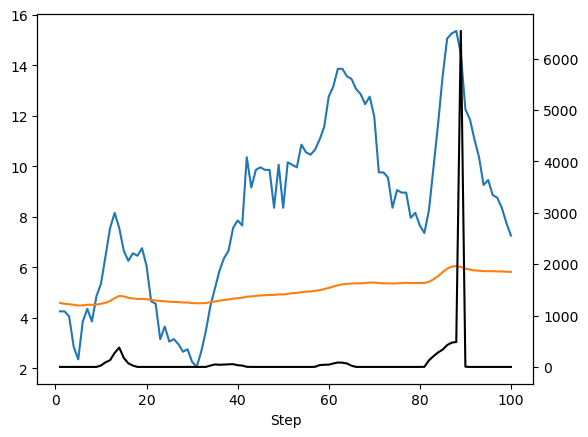

In [ ]:
## Visualize the data and understand its structure

# Case study

The case study in this notebook is a simple house. The boundary conditions (inputs) are the external temeprature and the solar radiation incident on the house envelope.

Recall the determinisitic state space model is governed by the following equations:

$$x = A x_t+Bu_t$$
$$y_t=Cx_t$$

Let's build a 1R1C model:

$$ A = \begin{bmatrix}
    -1.0/RC
\end{bmatrix} $$

$$ B = \begin{bmatrix}
    1.0/RC  & a/C & 1.0/C \\
\end{bmatrix} $$

$$ C = \begin{bmatrix}
    1 
\end{bmatrix} $$

$a$ here is the solar aperture given in $m^2$ and it is an additional parameter to identify.

In the following cell build a function that constructs these matrices for 1R1C state space model

In [ ]:
def build_continuous_matrices(R, C, a):
    ###
    # Build continuous-time state-space matrices for the thermal model
    ###
    return A, B, C

# Discritization of the matrices

Recall that we need to discritize the matrices as follows:

$$x_{[t+1]}=A_d​x_t + B​_du_t$$

where:

$$
A_d = e^{A T}
$$

$$
B_d​=A^{-1}​(A_d​−I)B​​
$$

In the following cell implement a function that transforms the contineuos contineuos statespace model into discrete (you can simply copy your work from the previous notebook)

In [ ]:
def discretize(time_step: float, Ac: np.ndarray, Bc: np.ndarray):
    ###
    # Discretize the contineous equations
    ###
    return Ad, Bd

# Forward simulation

Build a function that applies computes the indoor temperature at each time step. Recall how to do forward simulation:

$$x_{[t+1]}=A_d​x_t + B​_du_t$$

You can copy the forward simulation function from the previous notebook it should be similar except for the parameters it accept since in this notebook we use 1R1C model however, in the previous one we used 2R2C model.

In [ ]:

def forward_simulation(R, C, a, T_in_initial, T_ext, Qsolar, Qheat, time_step):
    ## Build system matrices
    Ac, Bc, C = build_continuous_matrices(R, C, a)
    Ad, Bd = discretize(time_step, Ac, Bc)

    ## Implement the forward simulation from scratch (you can get help from the previous notebook)

    return prediction

# Cost function

Since we want to do optimization, we will use the minimize function of scipy package. So we will have to define the cost function in a seperate function to give it as an argument to the scipy minimize function.

Recall from the slides that we try to minimize the negative log-likelihood function. The log-likelihood function for the deterministic model is: 

$$ \frac{−𝑛}{2}  \log⁡(2\pi\sigma^2 )− \frac{1}{2\sigma^2 } \Sigma_{j=1}^{n} (y_j - Cx_j)^2 $$

We might not care about the first term and the fraction multiplying the next term since they are constant and do not change according to parameters $\theta$ variation, so we can drop them and my log-likelihood function turns out to be as follows

$$ − \Sigma_{j=1}^{n} (y_j - Cx_j)^2 $$

Since we will use the minimize function, then we will need to use the negative log-likelihood. So the cost function for this problem becomes:

$$ \Sigma_{j=1}^{n} (y_j - Cx_j)^2 $$

You might have already noticed that the likelihood function here turns out to be exactly the sume of squares and that minimizing the likelihood function is exatcly minimizing the sume of squared resideuals. This is in fact correct for determinisitc models. In deterministic models the likelihood function reduced to the sum of squared residuals, however, in stochastic models not.

So in the following cell build a function that computes this cost. It should take as inputs all what is needed for the forward simulation function.

In [ ]:
def cost_function(params, T_in_initial, T_in, T_ext, Qsolar, Qheat, time_step):
    ###
    # Define the cost function for optimization
    ###
    return cost

# Solver

Now after having defined our model and and the cost function, now we should define the solver. We will use minimize function of scipy. So put it in ana encapsulator function called solve_optimization.

In [ ]:
def solve_optimization(R, C, a, T_in_initial, T_in, T_ext, Qsolar, Qheat, time_step):
    initial_params = [R, C, a]
    bounds = [(1e-5, None), (1e-5, None), (1e-5, None)]  # Example bounds

    ###
    # Use the minimize function from scipy.optimize to solve the optimization problem
    ###
    return result.x

# Split train and test sets

Now we cant split the data into training and testing sets and optimize the parameters in the training set and test them on the test set 

In [ ]:
sT = 3600 * 24  # You should have converted your timestep inot days
time_step = data.index[1] - data.index[0]  
###
# split the data into two dataframe one is called train_data and the other is called test_data
###


In [ ]:
# Training data
time_train = train_data.index.values
T_in_train = train_data['Tint'].values  # indoor air temperature
# Do the same for the other important variables


In [ ]:
# Testing data
time_test = test_data.index.values
T_in_test = test_data['Tint'].values
# Do the same for the other important variables

# Initialization of parameters

The solver needs initial values for the parameter you want to identify, so propose some initial values. Be careful that the quality of identification depends on the initial values proposed so they need to be reasonble

In [20]:
R = 0.1
C = 1e7/sT
a = 0.5

# Initial state not to be identified (you get them from the data the first value of Tint in the training and testing set)
Tint_initial_state_train = 4.59
Tint_initial_state_test = 9.59

# Run the solver

In [21]:
popt = solve_optimization(R, C, a, Tint_initial_state_train, T_in_train, T_ext_train, Qsolar_train, Qheat_train, time_step)
R_opt, C_opt, a_opt = popt
print(f"Optimized parameters: R={R_opt}, C={C_opt}, a={a_opt}")

Optimized parameters: R=0.14520772689006195, C=149.1342445082778, a=0.2072190089367268


# Validate



In [22]:
### prediction on training data
T_in_pred_train = forward_simulation(R_opt, C_opt, a_opt, Tint_initial_state_train, T_ext_train, Qsolar_train, Qheat_train, time_step)
T_in_pred_test = forward_simulation(R_opt, C_opt, a_opt, Tint_initial_state_test, T_ext_test, Qsolar_test, Qheat_test, time_step)


# Visualisation

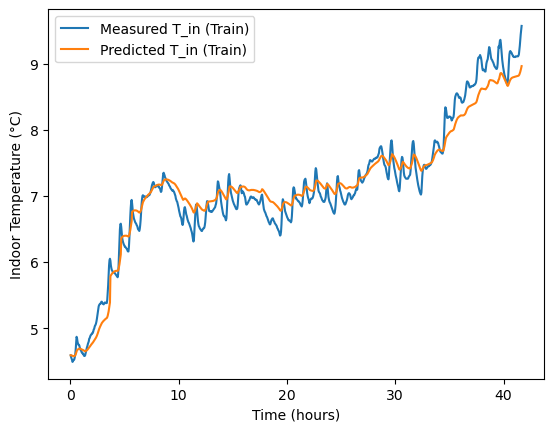

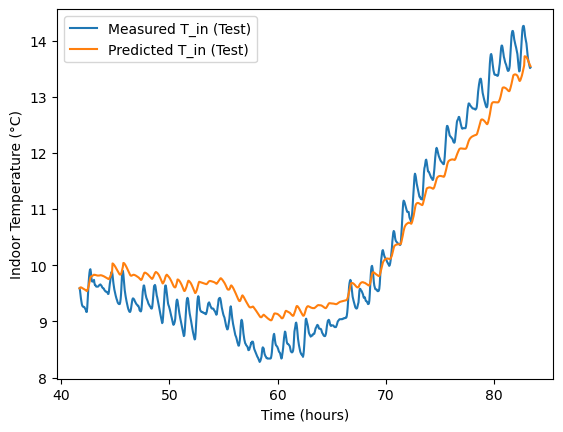

In [ ]:
# Visualize the predictions vs actual data for both training and testing sets

# Note

This model contains non identifiability. If you take a deeper look to the model you notice that there is a strong non identifiability between a and C. The heating power is all the time set to zero. You can also detect this by running different minimization from different initial guesses you will observe almost same prediction behaviour even for different set of values.

# Conclsion

In this notebook you ran a simple identification problem using scipy package. We used frequentist appraoches. Another approach can be used is the bayesian approach but this will be detailed in other notebooks.